In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
import zipfile
import io

with zipfile.ZipFile("student+performance.zip") as z:
    with zipfile.ZipFile(io.BytesIO(z.read("student.zip"))) as inner:
        df = pd.read_csv(inner.open("student-mat.csv"), sep=";")

print("Rows and columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.head())

Rows and columns: (395, 33)
Missing values: 0
Duplicate rows: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
df["passed"] = (df["G3"] >= 10).astype(int)
features = ["studytime", "absences", "failures", "G1", "G2", "goout", "health", "freetime"]
X = df[features]
y = df["passed"]
print("Pass/fail counts (1=pass, 0=fail):")
print(y.value_counts())

Pass/fail counts (1=pass, 0=fail):
passed
1    265
0    130
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=["Fail", "Pass"]))

Accuracy: 0.8734
              precision    recall  f1-score   support

        Fail       0.74      0.96      0.83        26
        Pass       0.98      0.83      0.90        53

    accuracy                           0.87        79
   macro avg       0.86      0.90      0.87        79
weighted avg       0.90      0.87      0.88        79



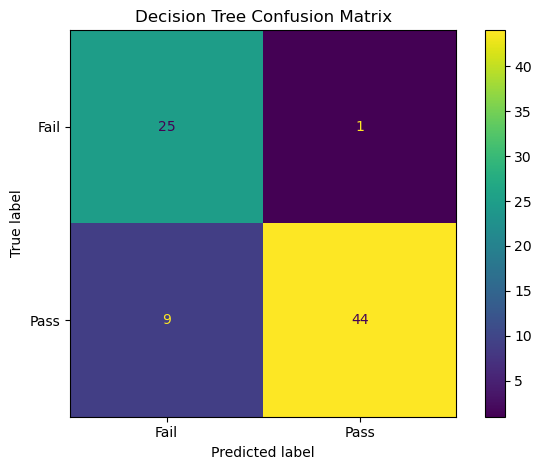

In [5]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Fail", "Pass"])
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=160)
plt.show()

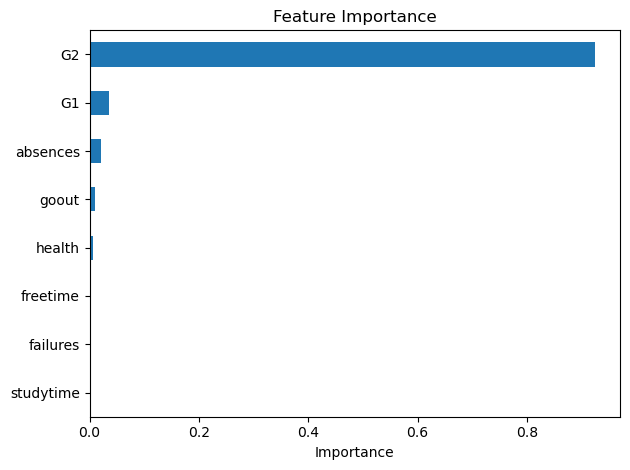

In [6]:
importance = pd.Series(model.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", title="Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=160)
plt.show()

In [7]:
mistakes = df.loc[X_test.index].copy()
mistakes["predicted_pass"] = y_pred
mistakes = mistakes[mistakes["passed"] != mistakes["predicted_pass"]]
columns = ["G1", "G2", "G3", "studytime", "absences", "failures", "passed", "predicted_pass"]
print("Total mistakes:", len(mistakes))
display(mistakes[columns].head(5))
mistakes[columns].to_csv("incorrect_predictions.csv", index_label="original_row_index")

Total mistakes: 10


,G1,G2,G3,studytime,absences,failures,passed,predicted_pass
208,9,9,10,1,6,0,1,0
43,8,8,11,1,0,0,1,0
283,8,9,10,2,4,0,1,0
281,11,9,10,1,19,1,1,0
2,7,8,10,2,10,3,1,0
